# Detector experimental PIOFlow

## 1. Imports e configuração

O código importa as bibliotecas, fixa a semente aleatória, localiza os dados e resultados no projeto ou no Colab e define os parâmetros do modelo, do treinamento e da avaliação. O treinamento começa desativado.


In [1]:
from pathlib import Path
import math
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
import tensorflow as tf
from tensorflow import keras
try:
    from google.colab import drive
except ImportError:
    drive = None

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)

candidatos_projeto = (
    Path.cwd() / "src" / "modelos_PIO",
    Path.cwd() / "modelos_PIO",
    Path.cwd(),
    Path.cwd().parent / "src" / "modelos_PIO",
)
PASTA_PROJETO = next(
    (c.resolve() for c in candidatos_projeto
     if (c / "midias" / "PIO" / "data").is_dir()),
    None,
)
if PASTA_PROJETO is not None:
    PASTA_PIO = PASTA_PROJETO / "midias" / "PIO" / "data"
    PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
    PASTAS_FRAMES = {
        stem: PASTA_PROJETO / "midias" / "raiar" / stem / "frames"
        for stem in ("camera-raiar", "video-galinhas2")
    }
else:
    PASTA_PIO = Path("/content/data")
    PASTA_RESULTADOS = Path("/content")
    PASTAS_FRAMES = {
        stem: Path("/content") for stem in ("camera-raiar", "video-galinhas2")
    }

TAMANHO = 640
CAIXAS_POR_CELULA = 4
BATCH_SIZE = 2
EPOCAS = 50
PACIENCIA = 8
TAXA_APRENDIZADO = 1e-3
LIMIAR_CONFIANCA = 0.25
LIMIAR_AP = 0.001
LIMIAR_IOU_NMS = 0.50
MAX_CANDIDATOS_NMS = 5000
MAX_DETECCOES = 1000
EXECUTAR_TREINO = False
CAMINHO_PESOS = PASTA_RESULTADOS / "detector_pio.weights.h5"
PESOS_CARREGADOS = False

if TAMANHO % 32:
    raise ValueError("TAMANHO deve ser múltiplo de 32.")
if CAIXAS_POR_CELULA < 1:
    raise ValueError("CAIXAS_POR_CELULA deve ser positivo.")
print("TensorFlow:", tf.__version__)
print("Dados PIO:", PASTA_PIO.resolve())
print("Checkpoint:", CAMINHO_PESOS.resolve())


TensorFlow: 2.21.0
Dados PIO: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\midias\PIO\data
Checkpoint: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\resultados\detector_pio.weights.h5


## 2. Leitura e validação da PIO

O código localiza as imagens e os rótulos das divisões de treino e validação, confere a classe e as coordenadas das caixas e ignora anotações sem área. Armazena os rótulos válidos e mostra o número de imagens e caixas em cada divisão.


In [2]:
EXTENSOES = {".jpg", ".jpeg", ".png"}

def listar_divisao(divisao):
    pasta_imagens = PASTA_PIO / "images" / divisao
    pasta_rotulos = PASTA_PIO / "labels" / divisao
    if not pasta_imagens.is_dir() or not pasta_rotulos.is_dir():
        arquivo_rar = PASTA_PIO.parent / "data.rar"
        detalhe = (f" O arquivo {arquivo_rar} existe, mas precisa ser extraído em {PASTA_PIO.parent}."
                   if arquivo_rar.is_file() else "")
        raise FileNotFoundError(
            f"Imagens e rótulos anotados da PIO não encontrados em {PASTA_PIO.resolve()}. "
            f"Esperado: {pasta_imagens} e {pasta_rotulos}. "
            "Confira se a extração criou PIO/data/images e PIO/data/labels."
            + detalhe
        )
    imagens = sorted(p for p in pasta_imagens.iterdir()
                     if p.is_file() and p.suffix.lower() in EXTENSOES)
    if not imagens:
        raise RuntimeError(f"Nenhuma imagem em {pasta_imagens}.")
    faltantes = [p.name for p in imagens
                 if not (pasta_rotulos / (p.stem + ".txt")).is_file()]
    if faltantes:
        raise RuntimeError(
            f"{len(faltantes)} imagens em {divisao} estão sem rótulo. "
            f"Exemplos: {faltantes[:5]}"
        )
    return imagens


def caminho_rotulo(caminho):
    divisao = caminho.parent.name
    return PASTA_PIO / "labels" / divisao / (caminho.stem + ".txt")


caixas_degeneradas = []

def ler_rotulos(caminho):
    caixas = []
    for numero, linha in enumerate(caminho.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not linha.strip():
            continue
        partes = linha.split()
        if len(partes) != 5:
            raise ValueError(f"{caminho}:{numero}: esperado '0 cx cy w h'.")
        try:
            classe = int(partes[0])
            cx, cy, w, h = map(float, partes[1:])
        except ValueError as erro:
            raise ValueError(f"{caminho}:{numero}: classe ou coordenadas inválidas.") from erro
        if classe != 0 or not all(map(math.isfinite, (cx, cy, w, h))):
            raise ValueError(f"{caminho}:{numero}: somente classe 0 e números finitos.")
        if w == 0 or h == 0:
            caixas_degeneradas.append(f"{caminho}:{numero}")
            continue
        if not (0 < w <= 1 and 0 < h <= 1 and 0 <= cx <= 1 and 0 <= cy <= 1):
            raise ValueError(f"{caminho}:{numero}: caixa fora do intervalo normalizado.")
        if (cx - w / 2 < -1e-6 or cy - h / 2 < -1e-6
                or cx + w / 2 > 1 + 1e-6 or cy + h / 2 > 1 + 1e-6):
            raise ValueError(f"{caminho}:{numero}: caixa ultrapassa a imagem.")
        caixas.append((cx, cy, w, h))
    return np.asarray(caixas, dtype=np.float32).reshape((-1, 4))


treino = listar_divisao("train")
validacao = listar_divisao("val")
imagens = treino + validacao
rotulos = {p: ler_rotulos(caminho_rotulo(p)) for p in imagens}
if not any(len(rotulos[p]) for p in treino):
    raise RuntimeError("A divisão de treino não contém galinhas anotadas.")
if not any(len(rotulos[p]) for p in validacao):
    raise RuntimeError("A divisão de validação não contém galinhas anotadas.")
print(f"Treino: {len(treino)} imagens, {sum(len(rotulos[p]) for p in treino)} caixas.")
print(f"Validação: {len(validacao)} imagens, {sum(len(rotulos[p]) for p in validacao)} caixas.")
if caixas_degeneradas:
    print(f"Caixas sem área ignoradas: {len(caixas_degeneradas)}. Exemplos: {caixas_degeneradas[:5]}")
print("Maior número de caixas em uma imagem:", max(map(len, rotulos.values())))

Treino: 1035 imagens, 253426 caixas.
Validação: 452 imagens, 73857 caixas.
Caixas sem área ignoradas: 5. Exemplos: ['C:\\Users\\Inteli\\Documents\\2026_02_Raiar\\src\\modelos_PIO\\midias\\PIO\\data\\labels\\train\\C-W3-0016.txt:332', 'C:\\Users\\Inteli\\Documents\\2026_02_Raiar\\src\\modelos_PIO\\midias\\PIO\\data\\labels\\train\\C-W3-0063.txt:334', 'C:\\Users\\Inteli\\Documents\\2026_02_Raiar\\src\\modelos_PIO\\midias\\PIO\\data\\labels\\train\\C-W6-0128.txt:149', 'C:\\Users\\Inteli\\Documents\\2026_02_Raiar\\src\\modelos_PIO\\midias\\PIO\\data\\labels\\val\\C-W3-V0038.txt:301', 'C:\\Users\\Inteli\\Documents\\2026_02_Raiar\\src\\modelos_PIO\\midias\\PIO\\data\\labels\\val\\P-W2-V0014.txt:86']
Maior número de caixas em uma imagem: 1151


## 3. Construção do detector

O código define os blocos da rede, constrói as três saídas de detecção nas escalas P3, P4 e P5 e mostra a quantidade de parâmetros e o formato das saídas.


In [4]:
def conv_bn_silu(x, canais, kernel=3, passo=1):
    x = keras.layers.Conv2D(canais, kernel, strides=passo, padding="same",
                            use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    return keras.layers.Activation("swish")(x)


def bottleneck(x, canais, atalho=True):
    y = conv_bn_silu(x, canais, 3)
    y = conv_bn_silu(y, canais, 3)
    if atalho and x.shape[-1] == canais:
        y = keras.layers.Add()([x, y])
    return y


def c3k2(x, canais, atalho=False, expansao=0.5):
    interno = max(8, int(canais * expansao))
    z = conv_bn_silu(x, interno * 2, 1)
    a = keras.layers.Lambda(lambda t: t[..., :interno])(z)
    b = keras.layers.Lambda(lambda t: t[..., interno:])(z)
    c = bottleneck(b, interno, atalho)
    return conv_bn_silu(keras.layers.Concatenate()([a, b, c]), canais, 1)


def sppf(x, canais):
    x = conv_bn_silu(x, canais // 2, 1)
    p1 = keras.layers.MaxPool2D(5, strides=1, padding="same")(x)
    p2 = keras.layers.MaxPool2D(5, strides=1, padding="same")(p1)
    p3 = keras.layers.MaxPool2D(5, strides=1, padding="same")(p2)
    return conv_bn_silu(keras.layers.Concatenate()([x, p1, p2, p3]), canais, 1)


def c2psa(x, canais):
    interno = canais // 2
    z = conv_bn_silu(x, canais, 1)
    a = keras.layers.Lambda(lambda t: t[..., :interno])(z)
    b = keras.layers.Lambda(lambda t: t[..., interno:])(z)
    h, w = int(b.shape[1]), int(b.shape[2])
    seq = keras.layers.Reshape((h * w, interno))(b)
    att = keras.layers.MultiHeadAttention(num_heads=4, key_dim=interno // 4)(seq, seq)
    seq = keras.layers.Add()([seq, att])
    ff = keras.layers.Dense(interno * 2, activation="swish")(seq)
    seq = keras.layers.Add()([seq, keras.layers.Dense(interno)(ff)])
    b = keras.layers.Reshape((h, w, interno))(seq)
    return conv_bn_silu(keras.layers.Concatenate()([a, b]), canais, 1)


def cabeca(x, canais):
    x = conv_bn_silu(x, canais, 3)
    x = conv_bn_silu(x, canais, 3)
    vies = [-4., 0., 0., -4., -4.] * CAIXAS_POR_CELULA
    logits = keras.layers.Conv2D(
        5 * CAIXAS_POR_CELULA, 1,
        bias_initializer=keras.initializers.Constant(vies)
    )(x)
    return keras.layers.Reshape(
        (int(x.shape[1]), int(x.shape[2]), CAIXAS_POR_CELULA, 5)
    )(logits)

def criar_detector(tamanho=640):
    entrada = keras.Input((tamanho, tamanho, 3))
    x = conv_bn_silu(entrada, 16, 3, 2)
    x = conv_bn_silu(x, 32, 3, 2)
    x = c3k2(x, 64, expansao=0.25)
    x = conv_bn_silu(x, 64, 3, 2)
    p3 = c3k2(x, 128, expansao=0.25)
    x = conv_bn_silu(p3, 128, 3, 2)
    p4 = c3k2(x, 128, atalho=True)
    x = conv_bn_silu(p4, 256, 3, 2)
    x = c3k2(x, 256, atalho=True)
    x = sppf(x, 256)
    p5 = c2psa(x, 256)

    x = keras.layers.UpSampling2D(2, interpolation="nearest")(p5)
    topo_p4 = c3k2(keras.layers.Concatenate()([x, p4]), 128)
    x = keras.layers.UpSampling2D(2, interpolation="nearest")(topo_p4)
    topo_p3 = c3k2(keras.layers.Concatenate()([x, p3]), 64)
    x = conv_bn_silu(topo_p3, 64, 3, 2)
    base_p4 = c3k2(keras.layers.Concatenate()([x, topo_p4]), 128)
    x = conv_bn_silu(base_p4, 128, 3, 2)
    base_p5 = c3k2(keras.layers.Concatenate()([x, p5]), 256, atalho=True)
    return keras.Model(entrada, [cabeca(topo_p3, 64),
                                cabeca(base_p4, 128),
                                cabeca(base_p5, 256)],
                       name="detector_galinhas_aleatorio")


modelo = criar_detector(TAMANHO)
print("Parâmetros:", f"{modelo.count_params():,}")
print("Saídas:", [tuple(s.shape) for s in modelo.outputs])
assert [tuple(s.shape[1:]) for s in modelo.outputs] == [
    (TAMANHO // 8, TAMANHO // 8, CAIXAS_POR_CELULA, 5),
    (TAMANHO // 16, TAMANHO // 16, CAIXAS_POR_CELULA, 5),
    (TAMANHO // 32, TAMANHO // 32, CAIXAS_POR_CELULA, 5),
]


Parâmetros: 4,095,532
Saídas: [(None, 80, 80, 4, 5), (None, 40, 40, 4, 5), (None, 20, 20, 4, 5)]


## 4. Preparo dos dados e das previsões

O código redimensiona imagens e caixas com bordas, cria alvos para as três escalas, aplica as transformações usadas no treino e monta os conjuntos TensorFlow. Também define a função que decodifica previsões e aplica supressão de caixas sobrepostas.


In [3]:
def carregar_imagem_e_caixas(caminho, caixas):
    with Image.open(caminho) as arquivo:
        imagem = arquivo.convert("RGB")
    largura, altura = imagem.size
    escala = min(TAMANHO / largura, TAMANHO / altura)
    nova_largura = min(TAMANHO, round(largura * escala))
    nova_altura = min(TAMANHO, round(altura * escala))
    desloc_x = (TAMANHO - nova_largura) // 2
    desloc_y = (TAMANHO - nova_altura) // 2
    reduzida = imagem.resize((nova_largura, nova_altura), Image.Resampling.BILINEAR)
    tela = Image.new("RGB", (TAMANHO, TAMANHO), (114, 114, 114))
    tela.paste(reduzida, (desloc_x, desloc_y))
    ajustadas = caixas.copy()
    if len(ajustadas):
        ajustadas[:, 0] = (caixas[:, 0] * nova_largura + desloc_x) / TAMANHO
        ajustadas[:, 1] = (caixas[:, 1] * nova_altura + desloc_y) / TAMANHO
        ajustadas[:, 2] = caixas[:, 2] * nova_largura / TAMANHO
        ajustadas[:, 3] = caixas[:, 3] * nova_altura / TAMANHO
    return np.asarray(tela, dtype=np.float32) / 255.0, ajustadas


VIZINHOS = ((0, 0), (-1, 0), (0, -1), (0, 1), (1, 0),
            (-1, -1), (-1, 1), (1, -1), (1, 1))


def criar_alvos(caixas, nome):
    alvos = [np.zeros((TAMANHO // s, TAMANHO // s, CAIXAS_POR_CELULA, 5),
                      dtype=np.float32) for s in (8, 16, 32)]
    for cx, cy, w, h in caixas:
        maior_lado = max(w, h) * TAMANHO
        preferido = 0 if maior_lado < 64 else (1 if maior_lado < 128 else 2)
        niveis = sorted(range(3), key=lambda nivel: abs(nivel - preferido))
        atribuido = False
        for nivel in niveis:
            mapa = alvos[nivel]
            grade = mapa.shape[0]
            centro_x = cx * grade
            centro_y = cy * grade
            coluna_base = min(grade - 1, int(centro_x))
            linha_base = min(grade - 1, int(centro_y))
            for dl, dc in VIZINHOS:
                linha, coluna = linha_base + dl, coluna_base + dc
                if not (0 <= linha < grade and 0 <= coluna < grade):
                    continue
                dx, dy = centro_x - coluna, centro_y - linha
                if not (-0.5 <= dx <= 1.5 and -0.5 <= dy <= 1.5):
                    continue
                for slot in range(CAIXAS_POR_CELULA):
                    if mapa[linha, coluna, slot, 0] == 0:
                        mapa[linha, coluna, slot] = (1., dx, dy, w, h)
                        atribuido = True
                        break
                if atribuido:
                    break
            if atribuido:
                break
        if not atribuido:
            raise ValueError(
                f"{nome}: não há posição livre para uma galinha. "
                "Aumente CAIXAS_POR_CELULA ou TAMANHO."
            )
    return tuple(alvos)


def aumentar_imagem(imagem, caixas):
    if random.random() < 0.5:
        imagem = np.flip(imagem, axis=1).copy()
        caixas = caixas.copy()
        caixas[:, 0] = 1.0 - caixas[:, 0]
    if random.random() < 0.3:
        cinza = imagem.mean(axis=2, keepdims=True)
        imagem = np.repeat(cinza, 3, axis=2)
    fator = random.uniform(0.8, 1.2)
    imagem = np.clip(imagem * fator, 0, 1).astype(np.float32)
    return imagem, caixas


def gerar_dataset(caminhos, aumentar=False):
    def exemplos():
        ordem = list(caminhos)
        if aumentar:
            random.shuffle(ordem)
        for caminho in ordem:
            imagem, caixas = carregar_imagem_e_caixas(caminho, rotulos[caminho])
            if aumentar:
                imagem, caixas = aumentar_imagem(imagem, caixas)
            yield imagem, criar_alvos(caixas, caminho.name)
    assinatura = (
        tf.TensorSpec((TAMANHO, TAMANHO, 3), tf.float32),
        tuple(tf.TensorSpec((TAMANHO // s, TAMANHO // s, CAIXAS_POR_CELULA, 5),
                            tf.float32) for s in (8, 16, 32))
    )
    return (tf.data.Dataset.from_generator(exemplos, output_signature=assinatura)
            .batch(BATCH_SIZE).prefetch(1))


dataset_treino = gerar_dataset(treino, aumentar=True)
dataset_validacao = gerar_dataset(validacao)
print("Datasets preparados.")


def prever_caixas(caminho, caixas_reais, limiar):
    imagem, anotadas = carregar_imagem_e_caixas(caminho, caixas_reais)
    saidas = modelo.predict(imagem[None, ...], verbose=0)
    todas_caixas, todas_confiancas = [], []

    for logits in saidas:
        bruto = logits[0]
        grade = bruto.shape[0]
        presenca = tf.sigmoid(bruto[..., 0]).numpy()
        linhas, colunas, slots = np.where(presenca >= limiar)
        if not len(linhas):
            continue
        deslocamentos = (
            2.0 * tf.sigmoid(bruto[..., 1:3]).numpy() - 0.5
        )[linhas, colunas, slots]
        tamanhos = tf.sigmoid(bruto[..., 3:5]).numpy()[linhas, colunas, slots]
        cx = (colunas + deslocamentos[:, 0]) / grade
        cy = (linhas + deslocamentos[:, 1]) / grade
        largura, altura = tamanhos[:, 0], tamanhos[:, 1]
        caixas = np.stack([
            np.maximum(0, cy - altura / 2),
            np.maximum(0, cx - largura / 2),
            np.minimum(1, cy + altura / 2),
            np.minimum(1, cx + largura / 2),
        ], axis=-1).astype(np.float32)
        validas = (caixas[:, 2] > caixas[:, 0]) & (caixas[:, 3] > caixas[:, 1])
        todas_caixas.append(caixas[validas])
        todas_confiancas.append(presenca[linhas, colunas, slots][validas])

    if not todas_caixas:
        return imagem, anotadas, np.empty((0, 4), np.float32), np.empty(0, np.float32)
    caixas = np.concatenate(todas_caixas)
    confiancas = np.concatenate(todas_confiancas).astype(np.float32)
    if len(confiancas) > MAX_CANDIDATOS_NMS:
        maiores = np.argpartition(confiancas, -MAX_CANDIDATOS_NMS)[-MAX_CANDIDATOS_NMS:]
        caixas, confiancas = caixas[maiores], confiancas[maiores]
    indices = tf.image.non_max_suppression(
        caixas, confiancas, max_output_size=MAX_DETECCOES,
        iou_threshold=LIMIAR_IOU_NMS,
    ).numpy()
    indices = indices[np.argsort(-confiancas[indices], kind="stable")]
    return imagem, anotadas, caixas[indices], confiancas[indices]


Datasets preparados.


## 5. Treinamento e carregamento dos pesos

O código define a função de perda e compila o detector. Quando o treinamento está ativado, treina a rede e salva os pesos em um novo caminho; caso contrário, carrega o checkpoint existente.


In [5]:
def perda_deteccao(real, previsto):
    presenca = real[..., 0]
    entropia = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=presenca, logits=previsto[..., 0])
    pesos = tf.where(presenca > 0.5, 1.0, 0.01)
    positivos = tf.maximum(tf.reduce_sum(presenca), 1.0)
    perda_objeto = tf.reduce_sum(entropia * pesos) / positivos

    deslocamentos = 2.0 * tf.sigmoid(previsto[..., 1:3]) - 0.5
    tamanhos = tf.sigmoid(previsto[..., 3:5])
    coordenadas = tf.concat([deslocamentos, tamanhos], axis=-1)
    perda_caixa = tf.reduce_sum(
        tf.abs(real[..., 1:5] - coordenadas) * presenca[..., None]
    ) / positivos
    return perda_objeto + 10.0 * perda_caixa

modelo.compile(
    optimizer=keras.optimizers.Adam(TAXA_APRENDIZADO),
    loss=[perda_deteccao] * 3,
)
historico = None
if EXECUTAR_TREINO:
    if CAMINHO_PESOS.exists():
        raise FileExistsError(
            f"{CAMINHO_PESOS} já existe. Escolha outro caminho para preservar o checkpoint."
        )
    CAMINHO_PESOS.parent.mkdir(parents=True, exist_ok=True)
    historico = modelo.fit(
        dataset_treino,
        validation_data=dataset_validacao,
        epochs=EPOCAS,
        callbacks=[keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PACIENCIA, restore_best_weights=True
        )],
    )
    modelo.save_weights(str(CAMINHO_PESOS))
    print("Pesos treinados salvos em:", CAMINHO_PESOS)
else:
    if not CAMINHO_PESOS.is_file():
        raise FileNotFoundError(
            f"Checkpoint não encontrado: {CAMINHO_PESOS}. "
            "Coloque o arquivo salvo nesse caminho ou configure outro."
        )
    modelo.load_weights(str(CAMINHO_PESOS))
    print("Checkpoint carregado:", CAMINHO_PESOS)
PESOS_CARREGADOS = True


Checkpoint carregado: C:\Users\Inteli\Documents\2026_02_Raiar\src\modelos_PIO\resultados\detector_pio.weights.h5


C:\Users\Inteli\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 332 variables. 
  saveable.load_own_variables(store)


## 6. Histórico do treinamento

O código reúne as perdas registradas em cada época, mostra uma tabela e traça as curvas de treino e validação para a perda total e as três escalas. Também identifica a época com a menor perda de validação.


Histórico: execução original, transcrita dos logs salvos no notebook
Época    Treino      Val.        P3    Val.P3        P4    Val.P4        P5    Val.P5
    1    8.8488    6.1564    5.3368    4.7196    3.4479    1.4334    0.0604    0.0033
    2    6.1095    5.1621    4.2114    4.1700    1.8943    0.9912    0.0018    0.0009
    3    5.5397    4.8210    3.8990    3.9302    1.6447    0.8905    0.0006    0.0004
    4    5.1606    4.6749    3.7068    3.8823    1.4527    0.7924    0.0003    0.0002
    5    4.9136    4.3920    3.5827    3.6200    1.3296    0.7719    0.0002    0.0001
    6    4.7469    4.4299    3.4620    3.6074    1.2837    0.8224    0.0001    0.0001
    7    4.6217    4.5487    3.3715    3.7889    1.2490    0.7597    0.0001    0.0001
    8    4.4205    4.1915    3.3149    3.4450    1.1076    0.7465    0.0000    0.0000
    9    4.3370    4.1915    3.2110    3.4500    1.1305    0.7415    0.0000    0.0000
   10    4.1592    4.2315    3.1476    3.4280    1.0142    0.8034    0.

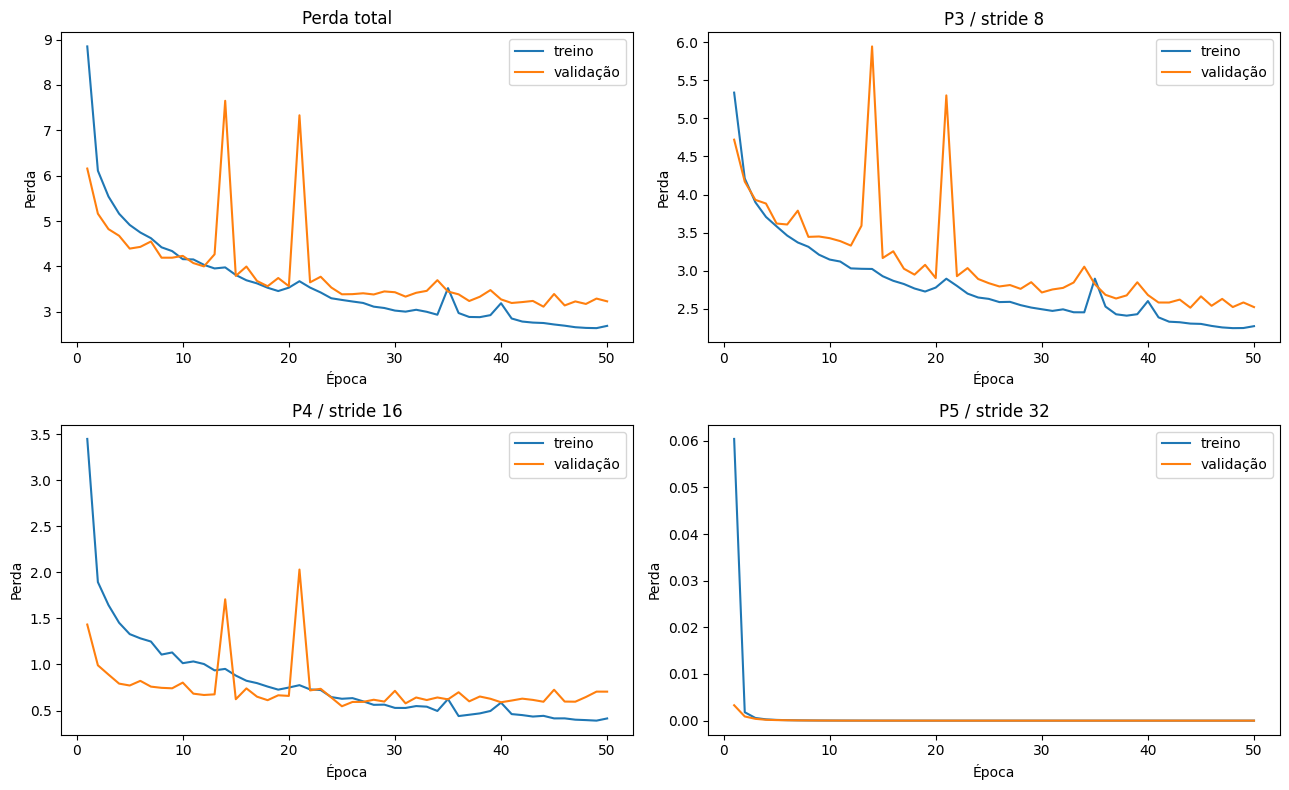

In [6]:
HISTORICO_ORIGINAL = [
    (1, 8.8488, 6.1564, 5.3368, 4.7196, 3.4479, 1.4334, 0.0604, 0.0033),
(2, 6.1095, 5.1621, 4.2114, 4.17, 1.8943, 0.9912, 0.0018, 0.00089605),
(3, 5.5397, 4.821, 3.899, 3.9302, 1.6447, 0.8905, 0.00057383, 0.00038578),
(4, 5.1606, 4.6749, 3.7068, 3.8823, 1.4527, 0.7924, 0.00027719, 0.000184),
(5, 4.9136, 4.392, 3.5827, 3.62, 1.3296, 0.7719, 0.0001554, 0.00011481),
(6, 4.7469, 4.4299, 3.462, 3.6074, 1.2837, 0.8224, 9.6115e-05, 8.4764e-05),
(7, 4.6217, 4.5487, 3.3715, 3.7889, 1.249, 0.7597, 6.3148e-05, 5.2259e-05),
(8, 4.4205, 4.1915, 3.3149, 3.445, 1.1076, 0.7465, 4.255e-05, 3.9361e-05),
(9, 4.337, 4.1915, 3.211, 3.45, 1.1305, 0.7415, 2.9264e-05, 2.5998e-05),
(10, 4.1592, 4.2315, 3.1476, 3.428, 1.0142, 0.8034, 2.1003e-05, 1.8765e-05),
(11, 4.1529, 4.0729, 3.1215, 3.3894, 1.0329, 0.6834, 1.5518e-05, 1.2406e-05),
(12, 4.0339, 3.9996, 3.0317, 3.3307, 1.005, 0.6689, 1.0781e-05, 8.6921e-06),
(13, 3.9545, 4.2665, 3.0263, 3.5906, 0.936, 0.6758, 7.9465e-06, 6.0224e-06),
(14, 3.9775, 7.6502, 3.0242, 5.9428, 0.9521, 1.7074, 6.0037e-06, 3.196e-06),
(15, 3.8099, 3.7904, 2.9292, 3.1675, 0.8796, 0.6229, 4.4151e-06, 4.1536e-06),
(16, 3.6937, 3.9965, 2.8688, 3.256, 0.8235, 0.7405, 3.2369e-06, 3.3203e-06),
(17, 3.6252, 3.6781, 2.8268, 3.0275, 0.7977, 0.6506, 2.3387e-06, 2.4387e-06),
(18, 3.5289, 3.5624, 2.768, 2.9499, 0.7603, 0.6125, 1.7519e-06, 1.4568e-06),
(19, 3.4563, 3.7436, 2.7282, 3.078, 0.7269, 0.6656, 1.3029e-06, 2.9509e-06),
(20, 3.5309, 3.5639, 2.7803, 2.9049, 0.7497, 0.659, 1.0366e-06, 9.7234e-07),
(21, 3.6728, 7.3309, 2.8964, 5.3006, 0.7755, 2.0303, 7.5002e-07, 5.0766e-07),
(22, 3.5326, 3.6485, 2.8021, 2.9298, 0.7294, 0.7187, 5.3581e-07, 4.1169e-07),
(23, 3.4248, 3.7717, 2.7011, 3.0356, 0.7227, 0.7362, 3.9632e-07, 3.3367e-07),
(24, 3.2972, 3.5342, 2.6498, 2.8927, 0.6463, 0.6415, 3.0309e-07, 3.2563e-07),
(25, 3.2603, 3.3845, 2.6319, 2.8378, 0.6279, 0.5467, 2.3405e-07, 2.0767e-07),
(26, 3.2259, 3.388, 2.5898, 2.7946, 0.6349, 0.5934, 1.7645e-07, 1.439e-07),
(27, 3.1939, 3.4072, 2.5929, 2.8132, 0.6001, 0.594, 1.3315e-07, 1.1155e-07),
(28, 3.1121, 3.3807, 2.5497, 2.7634, 0.562, 0.6173, 1.0178e-07, 8.7113e-08),
(29, 3.0826, 3.448, 2.5179, 2.8507, 0.5641, 0.5974, 7.8059e-08, 8.2936e-08),
(30, 3.0255, 3.43, 2.4958, 2.7159, 0.5288, 0.7141, 5.9779e-08, 4.9189e-08),
(31, 3.0024, 3.3334, 2.4741, 2.7553, 0.5283, 0.5781, 4.5812e-08, 4.0169e-08),
(32, 3.0435, 3.4176, 2.4947, 2.7758, 0.5487, 0.6418, 3.5436e-08, 2.9782e-08),
(33, 2.9985, 3.4607, 2.4563, 2.8465, 0.5421, 0.6142, 2.8307e-08, 2.6949e-08),
(34, 2.9341, 3.6959, 2.4555, 3.054, 0.4955, 0.6419, 2.148e-08, 1.8353e-08),
(35, 3.5206, 3.4452, 2.8971, 2.8238, 0.6246, 0.6214, 1.6951e-08, 1.5471e-08),
(36, 2.9716, 3.3838, 2.531, 2.685, 0.4402, 0.6987, 1.3172e-08, 1.1212e-08),
(37, 2.885, 3.2368, 2.4298, 2.6368, 0.4545, 0.6, 1.0391e-08, 9.7114e-09),
(38, 2.8808, 3.3304, 2.4117, 2.6779, 0.4692, 0.6525, 8.3569e-09, 7.9266e-09),
(39, 2.9251, 3.4774, 2.4309, 2.8495, 0.4955, 0.6279, 7.0204e-09, 6.4494e-09),
(40, 3.1879, 3.2726, 2.603, 2.6826, 0.586, 0.5901, 6.0591e-09, 5.1585e-09),
(41, 2.8511, 3.193, 2.3896, 2.5842, 0.4616, 0.6087, 4.7459e-09, 4.3997e-09),
(42, 2.7839, 3.2132, 2.3325, 2.5839, 0.4507, 0.6292, 3.8964e-09, 4.2755e-09),
(43, 2.7609, 3.2381, 2.3254, 2.6224, 0.4349, 0.6157, 3.3345e-09, 3.456e-09),
(44, 2.7516, 3.1119, 2.3077, 2.5163, 0.4427, 0.5956, 2.7224e-09, 2.7513e-09),
(45, 2.7195, 3.3908, 2.3036, 2.6649, 0.4149, 0.7259, 2.3254e-09, 3.5351e-09),
(46, 2.6925, 3.1389, 2.2772, 2.5413, 0.4153, 0.5976, 2.0311e-09, 1.9319e-09),
(47, 2.6588, 3.2276, 2.2575, 2.6316, 0.401, 0.5961, 1.7468e-09, 1.594e-09),
(48, 2.6437, 3.1718, 2.2481, 2.5247, 0.3964, 0.6471, 1.5327e-09, 1.4909e-09),
(49, 2.6386, 3.2903, 2.2495, 2.5848, 0.3906, 0.7055, 1.351e-09, 1.2832e-09),
(50, 2.6886, 3.2293, 2.2741, 2.5241, 0.4143, 0.7052, 1.2059e-09, 1.635e-09)
]

if historico is None:
    linhas_historico = HISTORICO_ORIGINAL
    origem_historico = "execução original, transcrita dos logs salvos no notebook"
else:
    dados = historico.history
    perdas_escala = sorted(
        chave for chave in dados
        if chave.endswith("_loss") and not chave.startswith("val_")
    )
    if len(perdas_escala) != 3:
        raise RuntimeError(f"Esperadas três perdas por escala; encontradas {perdas_escala}.")
    linhas_historico = [
        (
            epoca + 1, dados["loss"][epoca], dados["val_loss"][epoca],
            dados[perdas_escala[0]][epoca], dados["val_" + perdas_escala[0]][epoca],
            dados[perdas_escala[1]][epoca], dados["val_" + perdas_escala[1]][epoca],
            dados[perdas_escala[2]][epoca], dados["val_" + perdas_escala[2]][epoca],
        )
        for epoca in range(len(dados["loss"]))
    ]
    origem_historico = "treinamento executado nesta sessão"

print("Histórico:", origem_historico)
print(
    f"{'Época':>5} {'Treino':>9} {'Val.':>9} "
    f"{'P3':>9} {'Val.P3':>9} {'P4':>9} {'Val.P4':>9} "
    f"{'P5':>9} {'Val.P5':>9}"
)
for linha in linhas_historico:
    print(f"{linha[0]:5d}" + "".join(f" {valor:9.4f}" for valor in linha[1:]))
melhor_epoca = min(linhas_historico, key=lambda linha: linha[2])
print(f"Menor perda de validação: época {melhor_epoca[0]} ({melhor_epoca[2]:.4f})")

epocas = [linha[0] for linha in linhas_historico]
figura, eixos = plt.subplots(2, 2, figsize=(13, 8))
for eixo, (col_treino, col_val, titulo) in zip(
    eixos.flat,
    [(1, 2, "Perda total"), (3, 4, "P3 / stride 8"),
     (5, 6, "P4 / stride 16"), (7, 8, "P5 / stride 32")],
):
    eixo.plot(epocas, [linha[col_treino] for linha in linhas_historico], label="treino")
    eixo.plot(epocas, [linha[col_val] for linha in linhas_historico], label="validação")
    eixo.set(title=titulo, xlabel="Época", ylabel="Perda")
    eixo.legend()
figura.tight_layout()
plt.show()


## 7. Avaliação das detecções na PIO

O código compara as caixas previstas com as anotações da validação PIO. Calcula sobreposição, associa previsões e rótulos e obtém verdadeiros positivos, falsos positivos, falsos negativos, precisão, recall, AP@0,50 e mAP@0,50:0,95.


In [7]:
if not PESOS_CARREGADOS:
    raise RuntimeError("Execute primeiro a célula que carrega o checkpoint.")
if not validacao:
    raise RuntimeError("A divisão de validação PIO está vazia.")

def caixas_anotadas_cantos(caixas_xywh):
    if not len(caixas_xywh):
        return np.empty((0, 4), dtype=np.float32)
    cx, cy, w, h = caixas_xywh.T
    return np.stack([cy - h / 2, cx - w / 2, cy + h / 2, cx + w / 2], axis=-1)

def matriz_iou(caixas_a, caixas_b):
    if not len(caixas_a) or not len(caixas_b):
        return np.zeros((len(caixas_a), len(caixas_b)), dtype=np.float32)
    superior_esquerdo = np.maximum(caixas_a[:, None, :2], caixas_b[None, :, :2])
    inferior_direito = np.minimum(caixas_a[:, None, 2:], caixas_b[None, :, 2:])
    lados = np.maximum(inferior_direito - superior_esquerdo, 0)
    intersecao = lados[..., 0] * lados[..., 1]
    area_a = np.prod(np.maximum(caixas_a[:, 2:] - caixas_a[:, :2], 0), axis=1)
    area_b = np.prod(np.maximum(caixas_b[:, 2:] - caixas_b[:, :2], 0), axis=1)
    uniao = area_a[:, None] + area_b[None, :] - intersecao
    return np.divide(
        intersecao, uniao, out=np.zeros_like(intersecao), where=uniao > 0
    )

def associar_caixas(ious, confiancas, limiar_iou):
    ordem = np.argsort(-confiancas, kind="stable")
    pareadas = np.zeros(len(confiancas), dtype=bool)
    anotadas_usadas = np.zeros(ious.shape[1], dtype=bool)
    if not ious.shape[1]:
        return pareadas
    for indice in ordem:
        sobreposicoes = np.where(anotadas_usadas, -1, ious[indice])
        melhor = int(np.argmax(sobreposicoes))
        if sobreposicoes[melhor] >= limiar_iou:
            pareadas[indice] = True
            anotadas_usadas[melhor] = True
    return pareadas

limiares_iou = np.round(np.arange(0.50, 1.00, 0.05), 2)
pontuacoes_ap = []
acertos_ap = [[] for _ in limiares_iou]
avaliacoes_pio = []
print("Avaliando as imagens de validação PIO com o checkpoint PIOFlow...")

for numero_imagem, caminho in enumerate(validacao, 1):
    _, anotadas_xywh, previstas, confiancas = prever_caixas(
        caminho, rotulos[caminho], LIMIAR_AP
    )
    anotadas = caixas_anotadas_cantos(anotadas_xywh)
    ious = matriz_iou(previstas, anotadas)
    pontuacoes_ap.append(confiancas)
    for indice, limiar_iou in enumerate(limiares_iou):
        acertos_ap[indice].append(associar_caixas(ious, confiancas, limiar_iou))

    selecionadas = confiancas >= LIMIAR_CONFIANCA
    pareadas = associar_caixas(
        ious[selecionadas], confiancas[selecionadas], 0.50
    )
    real = len(anotadas)
    prevista = int(selecionadas.sum())
    verdadeiros_positivos = int(pareadas.sum())
    avaliacoes_pio.append({
        "imagem": caminho.name,
        "real": real,
        "prevista": prevista,
        "erro": prevista - real,
        "tp": verdadeiros_positivos,
        "fp": prevista - verdadeiros_positivos,
        "fn": real - verdadeiros_positivos,
    })
    if numero_imagem % 50 == 0 or numero_imagem == len(validacao):
        print(f"Imagens avaliadas: {numero_imagem}/{len(validacao)}")

total_real = sum(item["real"] for item in avaliacoes_pio)
if not total_real:
    raise RuntimeError("A validação PIO não contém galinhas anotadas.")
total_tp = sum(item["tp"] for item in avaliacoes_pio)
total_fp = sum(item["fp"] for item in avaliacoes_pio)
total_fn = sum(item["fn"] for item in avaliacoes_pio)
pontuacoes = np.concatenate(pontuacoes_ap)
ordem_global = np.argsort(-pontuacoes, kind="stable")

def precisao_media(acertos):
    if not len(acertos):
        return 0.0
    verdadeiros = np.cumsum(acertos[ordem_global])
    precisao = verdadeiros / np.arange(1, len(acertos) + 1)
    recall = verdadeiros / total_real
    envelope = np.maximum.accumulate(precisao[::-1])[::-1]
    pontos = np.linspace(0, 1, 101)
    indices = np.searchsorted(recall, pontos, side="left")
    interpolada = np.zeros_like(pontos)
    validos = indices < len(envelope)
    interpolada[validos] = envelope[indices[validos]]
    return float(np.mean(interpolada))

valores_ap = [
    precisao_media(np.concatenate(acertos))
    for acertos in acertos_ap
]
metricas_pio = {
    "precisao": total_tp / (total_tp + total_fp) if total_tp + total_fp else 0.0,
    "recall": total_tp / (total_tp + total_fn),
    "map50": valores_ap[0],
    "map50_95": float(np.mean(valores_ap)),
}
print(
    f"PIO: {len(avaliacoes_pio)} imagens, {total_real} galinhas anotadas, "
    f"{total_tp} TP, {total_fp} FP e {total_fn} FN no limiar de confiança "
    f"{LIMIAR_CONFIANCA:.2f}."
)


Avaliando as imagens de validação PIO com o checkpoint PIOFlow...
Imagens avaliadas: 50/452
Imagens avaliadas: 100/452
Imagens avaliadas: 150/452
Imagens avaliadas: 200/452
Imagens avaliadas: 250/452
Imagens avaliadas: 300/452
Imagens avaliadas: 350/452
Imagens avaliadas: 400/452
Imagens avaliadas: 450/452
Imagens avaliadas: 452/452
PIO: 452 imagens, 73857 galinhas anotadas, 69510 TP, 133729 FP e 4347 FN no limiar de confiança 0.25.


## 8. Erro de contagem na PIO

O código compara, em cada imagem validada, a quantidade de caixas detectadas com a quantidade de galinhas anotadas. Calcula MAE, RMSE, MAPE, viés médio e os totais de anotações e detecções.


In [8]:
if "avaliacoes_pio" not in globals():
    raise RuntimeError("Execute primeiro a avaliação das detecções na PIO.")

reais = np.asarray([item["real"] for item in avaliacoes_pio], dtype=np.float64)
previstas = np.asarray([item["prevista"] for item in avaliacoes_pio], dtype=np.float64)
diferencas = previstas - reais
mae_contagem = float(np.mean(np.abs(diferencas)))
rmse_contagem = float(np.sqrt(np.mean(np.square(diferencas))))
vies_contagem = float(np.mean(diferencas))
com_galinhas = reais > 0
imagens_sem_galinhas = int((~com_galinhas).sum())
mape_contagem = (
    float(100 * np.mean(np.abs(diferencas[com_galinhas]) / reais[com_galinhas]))
    if np.any(com_galinhas) else None
)

linhas_resumo = [
    ("Precisão PIO (IoU 0,50)", f"{100 * metricas_pio['precisao']:.2f}%"),
    ("Recall PIO (IoU 0,50)", f"{100 * metricas_pio['recall']:.2f}%"),
    ("AP@0,50 PIO", f"{100 * metricas_pio['map50']:.2f}%"),
    ("mAP@0,50:0,95 PIO", f"{100 * metricas_pio['map50_95']:.2f}%"),
    ("MAE da contagem", f"{mae_contagem:.2f} galinhas/imagem"),
    ("RMSE da contagem", f"{rmse_contagem:.2f} galinhas/imagem"),
    ("MAPE da contagem", f"{mape_contagem:.2f}%" if mape_contagem is not None else "indefinido"),
    ("Viés médio da contagem", f"{vies_contagem:+.2f} galinhas/imagem"),
    ("Total anotado na validação", f"{int(reais.sum())} galinhas"),
    ("Total detectado na validação", f"{int(previstas.sum())} detecções"),
]


## 9. Tabela dos indicadores

O código imprime as métricas de detecção e contagem já calculadas e lista as dez imagens da PIO com as maiores diferenças de contagem.


In [11]:
if "linhas_resumo" not in globals():
    raise RuntimeError("Execute primeiro a célula de erro de contagem.")

largura_nome = max(len("Métrica"), *(len(nome) for nome, _ in linhas_resumo))
largura_valor = max(len("Resultado"), *(len(valor) for _, valor in linhas_resumo))
print(f"{'Métrica':<{largura_nome}} | {'Resultado':>{largura_valor}}")
print(f"{'-' * largura_nome}-+-{'-' * largura_valor}")
for nome, valor in linhas_resumo:
    print(f"{nome:<{largura_nome}} | {valor:>{largura_valor}}")

print(
    f"\nImagens avaliadas: {len(avaliacoes_pio)}; "
    f"imagens sem galinhas excluídas do MAPE: {imagens_sem_galinhas}."
)
print("\nMaiores diferenças de contagem (PIO):")
print(f"{'Imagem':<28} {'Real':>7} {'Detectadas':>12} {'Erro':>7}")
for item in sorted(avaliacoes_pio, key=lambda item: abs(item["erro"]), reverse=True)[:10]:
    print(
        f"{item['imagem']:<28} {item['real']:>7} "
        f"{item['prevista']:>12} {item['erro']:>+7}"
    )


Métrica                      |               Resultado
-----------------------------+------------------------
Precisão PIO (IoU 0,50)      |                  34.20%
Recall PIO (IoU 0,50)        |                  94.11%
AP@0,50 PIO                  |                  83.96%
mAP@0,50:0,95 PIO            |                  45.52%
MAE da contagem              |  286.24 galinhas/imagem
RMSE da contagem             |  310.17 galinhas/imagem
MAPE da contagem             |                 351.77%
Viés médio da contagem       | +286.24 galinhas/imagem
Total anotado na validação   |          73857 galinhas
Total detectado na validação |        203239 detecções

Imagens avaliadas: 452; imagens sem galinhas excluídas do MAPE: 0.

Maiores diferenças de contagem (PIO):
Imagem                          Real   Detectadas    Erro
P-W4-V0048.jpg                    31          878    +847
P-W4-V0045.jpg                    28          843    +815
P-W4-V0019.jpg                    27          746    +719
P

## 10. Inspeção dos vídeos da Raiar

O código seleciona até três frames de cada vídeo, desenha as caixas previstas, exibe a quantidade detectada em cada frame e mostra os quadros em uma grade.


Câmera Raiar | camera-raiar_t0000s.jpg: 405 detecções
Câmera Raiar | camera-raiar_t0300s.jpg: 417 detecções
Câmera Raiar | camera-raiar_t0598s.jpg: 381 detecções
Segundo vídeo | video-galinhas2_t0000s.jpg: 349 detecções
Segundo vídeo | video-galinhas2_t0008s.jpg: 376 detecções
Segundo vídeo | video-galinhas2_t0014s.jpg: 373 detecções


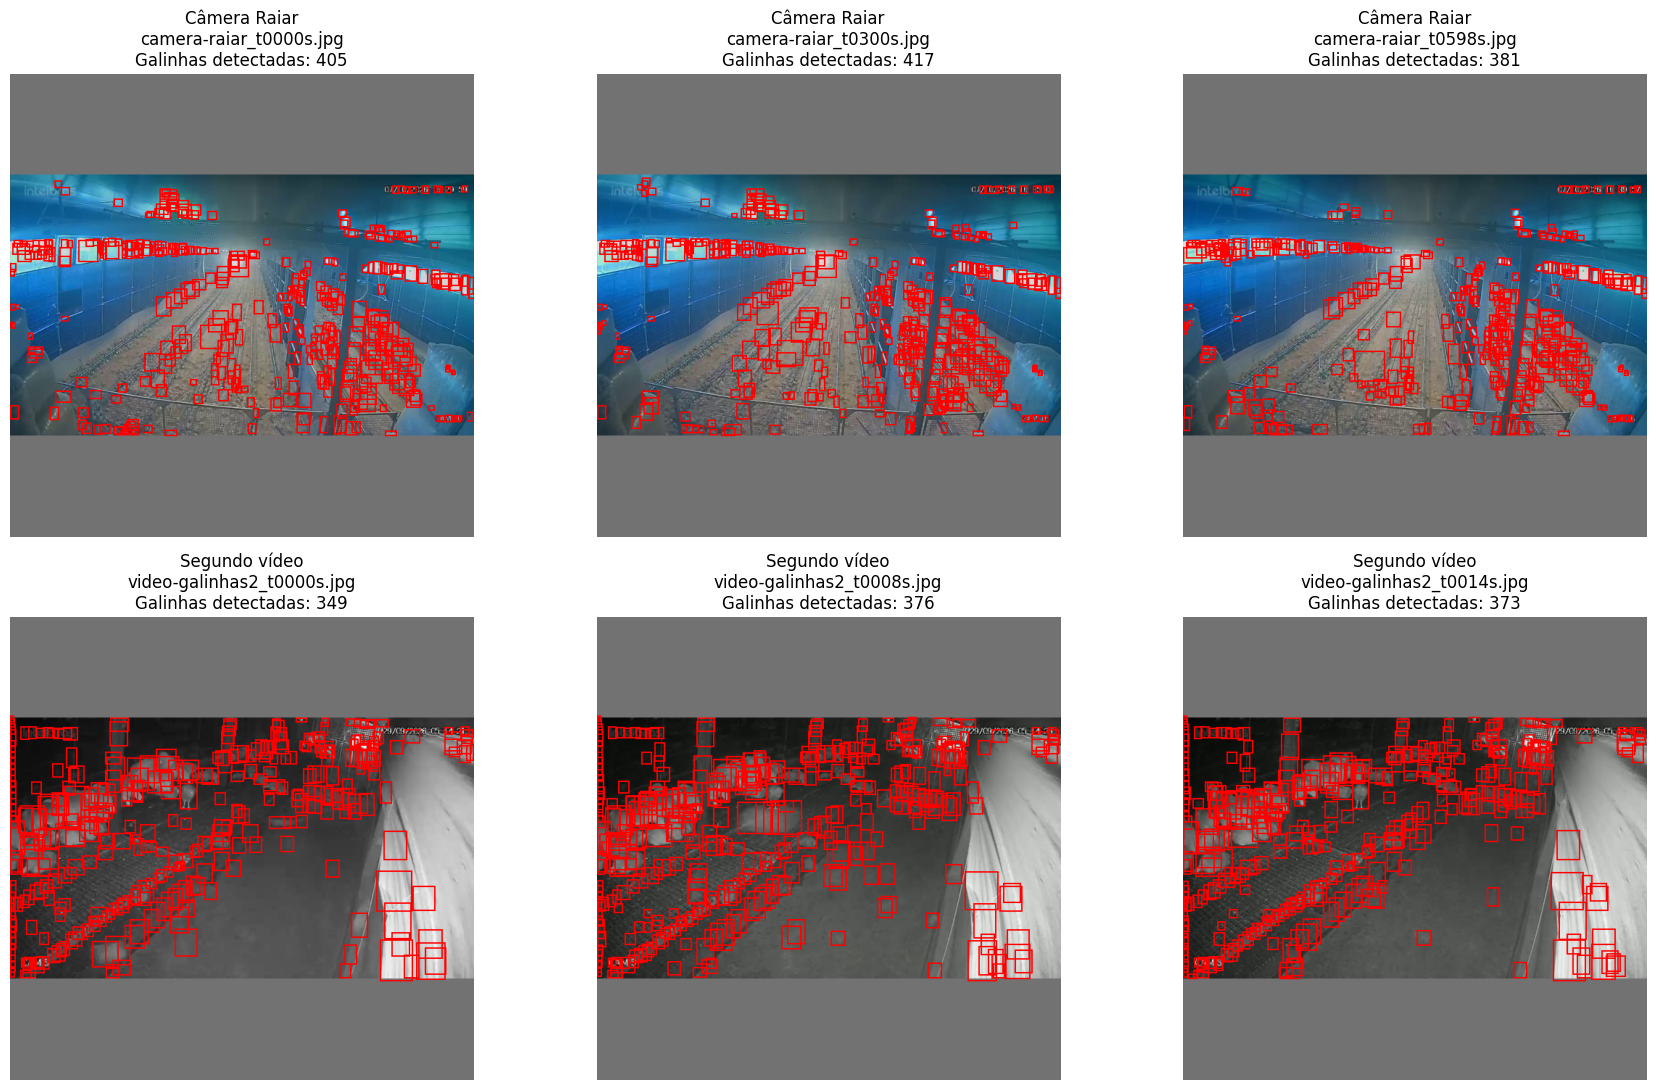

In [12]:
if not PESOS_CARREGADOS:
    raise RuntimeError("Execute primeiro a célula que carrega o checkpoint.")

grupos = {
    "Câmera Raiar": (
        PASTAS_FRAMES["camera-raiar"], "camera-raiar_t????s.jpg"
    ),
    "Segundo vídeo": (
        PASTAS_FRAMES["video-galinhas2"], "video-galinhas2_t????s.jpg"
    ),
}
for nome, (pasta, padrao) in grupos.items():
    if not list(pasta.glob(padrao)):
        raise FileNotFoundError(
            f"Não encontrei frames de {nome} em {pasta}. "
            "Gere os frames no notebook de análise ou ajuste PASTAS_FRAMES."
        )

figura, eixos = plt.subplots(2, 3, figsize=(18, 11))
for linha, (nome, (pasta, padrao)) in enumerate(grupos.items()):
    frames = sorted(pasta.glob(padrao))
    indices = list(dict.fromkeys((0, len(frames) // 2, len(frames) - 1)))
    for coluna, indice in enumerate(indices):
        caminho = frames[indice]
        imagem, _, caixas, _ = prever_caixas(
            caminho, np.empty((0, 4), dtype=np.float32), LIMIAR_CONFIANCA
        )
        vista = Image.fromarray((imagem * 255).astype(np.uint8))
        desenho = ImageDraw.Draw(vista)
        for ymin, xmin, ymax, xmax in caixas:
            desenho.rectangle(
                (xmin * TAMANHO, ymin * TAMANHO,
                 xmax * TAMANHO, ymax * TAMANHO),
                outline="red", width=2,
            )
        eixos[linha, coluna].imshow(vista)
        eixos[linha, coluna].set_title(
            f"{nome}\n{caminho.name}\nGalinhas detectadas: {len(caixas)}"
        )
        eixos[linha, coluna].axis("off")
        print(f"{nome} | {caminho.name}: {len(caixas)} detecções")
    for coluna in range(len(indices), 3):
        eixos[linha, coluna].axis("off")

figura.tight_layout()
plt.show()


## 11. Cópia opcional para o Google Drive

O código mantém a cópia desativada por padrão. Quando ativada no Colab, monta o Drive, copia o checkpoint para a pasta Raiar e confere o tamanho do arquivo copiado.


In [ ]:
COPIAR_PARA_DRIVE = False
if COPIAR_PARA_DRIVE:
    if drive is None:
        raise RuntimeError("Esta cópia exige um kernel do Google Colab.")
    if not CAMINHO_PESOS.is_file():
        raise FileNotFoundError(f"Checkpoint não encontrado: {CAMINHO_PESOS}")
    drive.mount("/content/drive")
    destino = Path("/content/drive/MyDrive/Raiar") / CAMINHO_PESOS.name
    destino.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(CAMINHO_PESOS, destino)
    if destino.stat().st_size != CAMINHO_PESOS.stat().st_size:
        raise IOError("A cópia para o Drive ficou incompleta.")
    print("Cópia concluída:", destino)
else:
    print("Cópia para o Drive desativada.")
